In [666]:
# 그래프관련 import 
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams['font.family'] = 'Malgun Gothic'
matplotlib.rcParams['axes.unicode_minus']=False

# 프로그램 
import pandas as pd
import numpy as np
from sklearn import svm,metrics
from sklearn.neighbors import KNeighborsClassifier # 분류 클래스
from sklearn.neighbors import KNeighborsRegressor # 예측 클래스
from sklearn.linear_model import LinearRegression # 예측 클래스
from sklearn.preprocessing import PolynomialFeatures # 다항특성 자동생성 라이브러리
from sklearn.linear_model import Ridge
from sklearn.linear_model import Lasso
from sklearn.preprocessing import OneHotEncoder
from sklearn.metrics import mean_absolute_error # 평균절대오차 오차범위 클래스
from sklearn.preprocessing import StandardScaler  # 정규화 클래스
from sklearn.model_selection import train_test_split

In [667]:
df = pd.read_csv('data/MultipleLinearRegressionData.csv')
df.head(5)

,hour,absent,place,score
0,0.5,3,Home,10
1,1.2,4,Library,8
2,1.8,2,Cafe,14
3,2.4,0,Cafe,26
4,2.6,2,Home,22


In [668]:
data = df.iloc[:,:-2].values
label = df.iloc[:,-1].values
# data
label

# df[['hour','absent']]
# data = df.iloc[:,:2].values
# data = df.iloc[:,:-2].values
# label = df.iloc[:,-1].values

# df[['hour','absent']]
# data = df.iloc[:,:-2].values
# label = df.iloc[:,-1].values
# label

array([ 10,   8,  14,  26,  22,  30,  42,  48,  38,  58,  60,  72,  62,
        68,  72,  58,  76,  86,  90, 100])

In [669]:
from sklearn.preprocessing import OneHotEncoder
place = df['place'].to_numpy().reshape(-1,1)   # 2차원배열로 가져옴.
encoder = OneHotEncoder(sparse_output=False,drop='first')
result = encoder.fit_transform(place)
# data + result 합치기
total_data = np.concatenate((data,result),axis=1)

In [670]:
# 학습데이터,테스트데이터 분리
train_data,test_data,train_label,test_label = \
train_test_split(total_data,label,random_state=42)

In [671]:
lr = LinearRegression()
lr.fit(train_data,train_label)
score = lr.score(train_data,train_label)
score2 = lr.score(test_data,test_label)
print(score)
print(score2)

0.9770255436151456
0.9551480880200325


In [672]:
predict = lr.predict(test_data)
print('예측점수 : ',predict)

예측점수 :  [-1.96441609 84.65989422 65.11068424  8.54709764 38.32995382]


In [673]:
place

array([['Home'],
       ['Library'],
       ['Cafe'],
       ['Cafe'],
       ['Home'],
       ['Home'],
       ['Library'],
       ['Library'],
       ['Home'],
       ['Cafe'],
       ['Cafe'],
       ['Cafe'],
       ['Library'],
       ['Cafe'],
       ['Library'],
       ['Home'],
       ['Cafe'],
       ['Home'],
       ['Library'],
       ['Library']], dtype=object)

In [674]:
df['place'].values
# 원핫 인코딩 작업 
place = df['place'].to_numpy().reshape(-1,1) # 2차원배열로 가져움 
encoder = OneHotEncoder(sparse_output=False,drop='first')
result = encoder.fit_transform(place)
result


array([[1., 0.],
       [0., 1.],
       [0., 0.],
       [0., 0.],
       [1., 0.],
       [1., 0.],
       [0., 1.],
       [0., 1.],
       [1., 0.],
       [0., 0.],
       [0., 0.],
       [0., 0.],
       [0., 1.],
       [0., 0.],
       [0., 1.],
       [1., 0.],
       [0., 0.],
       [1., 0.],
       [0., 1.],
       [0., 1.]])

In [675]:
# data + place 합치기
total_data = np.concatenate((data,result),axis=1)
total_data

array([[ 0.5,  3. ,  1. ,  0. ],
       [ 1.2,  4. ,  0. ,  1. ],
       [ 1.8,  2. ,  0. ,  0. ],
       [ 2.4,  0. ,  0. ,  0. ],
       [ 2.6,  2. ,  1. ,  0. ],
       [ 3.2,  0. ,  1. ,  0. ],
       [ 3.9,  0. ,  0. ,  1. ],
       [ 4.4,  0. ,  0. ,  1. ],
       [ 4.5,  5. ,  1. ,  0. ],
       [ 5. ,  1. ,  0. ,  0. ],
       [ 5.3,  2. ,  0. ,  0. ],
       [ 5.8,  0. ,  0. ,  0. ],
       [ 6. ,  3. ,  0. ,  1. ],
       [ 6.1,  1. ,  0. ,  0. ],
       [ 6.2,  1. ,  0. ,  1. ],
       [ 6.9,  4. ,  1. ,  0. ],
       [ 7.2,  2. ,  0. ,  0. ],
       [ 8.4,  1. ,  1. ,  0. ],
       [ 8.6,  1. ,  0. ,  1. ],
       [10. ,  0. ,  0. ,  1. ]])

In [676]:
# 학습데이터, 테스트데이터 분리 
train_data, test_data, train_label, test_label = train_test_split(data,label,random_state=42)
train_data
train_label

array([ 30,  72,  26,  90,  76,  68,  14,  58, 100,  22,  62,  48,  60,
        72,  42])

In [677]:
lr = LinearRegression()
lr.fit(train_data,train_label)
score = lr.score(train_data,train_label)
score2 = lr.score(test_data,test_label)
print(score)
print(score2)

0.9670590903587725
0.9353816842639381


In [678]:
predict = lr.predict(test_data)
print('예측점수 : ',predict)

예측점수 :  [ 2.93663479 90.22385347 71.15098863  9.54805238 44.25905494]


In [679]:
place[:5]
result[:5]

array([[1., 0.],
       [0., 1.],
       [0., 0.],
       [0., 0.],
       [1., 0.]])

In [680]:
predict = lr.predict(test_data)
print(predict)

[ 2.93663479 90.22385347 71.15098863  9.54805238 44.25905494]


In [681]:
train_data

array([[ 3.2,  0. ],
       [ 5.8,  0. ],
       [ 2.4,  0. ],
       [ 8.6,  1. ],
       [ 7.2,  2. ],
       [ 6.1,  1. ],
       [ 1.8,  2. ],
       [ 5. ,  1. ],
       [10. ,  0. ],
       [ 2.6,  2. ],
       [ 6. ,  3. ],
       [ 4.4,  0. ],
       [ 5.3,  2. ],
       [ 6.2,  1. ],
       [ 3.9,  0. ]])

In [682]:
train_data[0]

array([3.2, 0. ])

In [683]:
poly = PolynomialFeatures(degree=2,include_bias=False)
poly.fit(train_data)
train_poly = poly.transform(train_data)
test_poly = poly.transform(test_data)
test_poly

array([[ 0.5 ,  3.  ,  0.25,  1.5 ,  9.  ],
       [ 8.4 ,  1.  , 70.56,  8.4 ,  1.  ],
       [ 6.9 ,  4.  , 47.61, 27.6 , 16.  ],
       [ 1.2 ,  4.  ,  1.44,  4.8 , 16.  ],
       [ 4.5 ,  5.  , 20.25, 22.5 , 25.  ]])

In [684]:
ss = StandardScaler()
ss.fit(train_poly)

train_scaled = ss.transform(train_poly)
test_scaled = ss.transform(test_poly)


In [685]:
alpha_list = [0.001,0.01,0.1,1,10,100]
train_score = []
test_score = []
for alpha in alpha_list:
    ridge = Ridge(alpha=alpha)
    ridge.fit(train_scaled,train_label)
    score = ridge.score(train_poly,train_label)
    score2 = ridge.score(test_poly,test_label)
    train_score.append(score)
    test_score.append(score2)


In [686]:
train_score
test_score

[-354.7190244752088,
 -291.99467309497436,
 -38.92462862332427,
 -107.14367735477573,
 -148.80397537947218,
 -15.040148209983034]

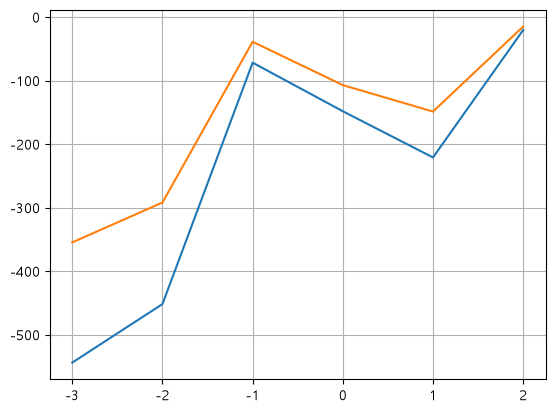

In [687]:
plt.plot(np.log10(alpha_list),train_score)
plt.plot(np.log10(alpha_list),test_score)
plt.grid()
plt.show()

In [688]:
lr = LinearRegression()
lr.fit(train_poly,train_label)

score = lr.score(train_poly,train_label)
score2 = lr.score(test_poly,test_label)

print('train 정확도 :', score)
print('test 정확도 :', score2) 

train 정확도 : 0.990849650473167
test 정확도 : 0.8653920861285799


In [689]:
lasso = Lasso(alpha=10)
lasso.fit(train_scaled,train_label)
print('[최종 모델 성능]')
print('훈련 정확도:', ridge.score(train_scaled, train_label))
print('테스트 정확도:', ridge.score(test_scaled, test_label))
print(np.sum(lasso.coef_)) 


[최종 모델 성능]
훈련 정확도: 0.3885175831666926
테스트 정확도: 0.24534829215249243
14.016826833392782


In [690]:
# 9. 예측 및 오차 확인
result = ridge.predict(test_scaled)
mae = mean_absolute_error(test_label, result)
print('평균 절대 오차(MAE):', mae)

평균 절대 오차(MAE): 22.135645224448645


In [691]:
lr = LinearRegression()
lr.fit(train_poly,train_label)

score = lr.score(train_poly,train_label)
score2 = lr.score(test_poly,test_label)

print('train 정확도 :', score)
print('test 정확도 :', score2) 

train 정확도 : 0.990849650473167
test 정확도 : 0.8653920861285799
